# 02c. Feature selection

Which features should go into the models, and in what form? I look at the features one at a time, in pairs against default, and together, and I use statistical tests so that the choices are not just a feeling.

**Rule for this notebook:** every choice here uses the **training years (2002-2004) only**. If the test years (2006-2007) influenced the choice of features, the test would no longer be fair. The years 2005-2007 appear in one place only, the stability table, and that table is for information. It is not used to pick features.

The result is two feature lists, saved to `data/processed/feature_sets.json`: a short one for logistic regression and a longer one for gradient boosting.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor

ROOT = Path.cwd().parent          # this notebook lives in notebooks/
sys.path.insert(0, str(ROOT / "src"))
from features import add_features, numeric_bins, categorical_bins, iv_table, iv_from_codes, permutation_iv, psi
import build_modelling_table as bmt

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 80)

table = pd.read_parquet(ROOT / "data" / "processed" / "loans.parquet")
full = add_features(table)                       # adds log_upb, ltv_gap, state_region, rate_spread
train = full[full["group"] == "train"].copy()    # from here on only the training years are used
y = train["default_24m"]

NUM = bmt.NUMERIC + ["log_upb", "ltv_gap", "rate_spread"]
CAT = bmt.CATEGORICAL + ["state_region"]
print(f"training loans: {len(train):,}, defaults: {int(y.sum()):,} ({100 * y.mean():.2f}%)")
print(f"{len(NUM)} number features and {len(CAT)} category features to look at")

training loans: 150,000, defaults: 1,048 (0.70%)
13 number features and 8 category features to look at


## 1. One variable at a time

What does each feature look like on its own: the middle, the spread, the extremes, and how lopsided it is (skew)? A skew far from 0 means a long tail on one side.

In [2]:
rows = []
for c in NUM:
    x = train[c]
    rows.append({"feature": c, "blank %": 100 * x.isna().mean(), "mean": x.mean(), "median": x.median(),
                 "std": x.std(), "min": x.min(), "max": x.max(), "skew": stats.skew(x.dropna())})
pd.DataFrame(rows).set_index("feature").round(2)

,blank %,mean,median,std,min,max,skew
feature,,,,,,,
credit_score,0.31,726.13,735.00,53.89,300.00,842.00,-0.86
mi_percent,0.00,3.03,0.00,8.22,0.00,52.00,2.58
num_units,0.00,1.03,1.00,0.22,1.00,4.00,9.63
combined_ltv,0.01,68.90,73.00,18.01,6.00,159.00,-0.69
dti,1.91,32.02,32.00,12.36,1.00,65.00,0.16
original_upb,0.00,147051.22,132500.00,74109.41,9000.00,690000.00,0.78
ltv,0.01,67.85,72.00,17.42,6.00,102.00,-0.76
interest_rate,0.00,5.85,5.88,0.65,3.75,9.39,0.31
loan_term,0.00,282.94,360.00,88.36,60.00,361.00,-0.37


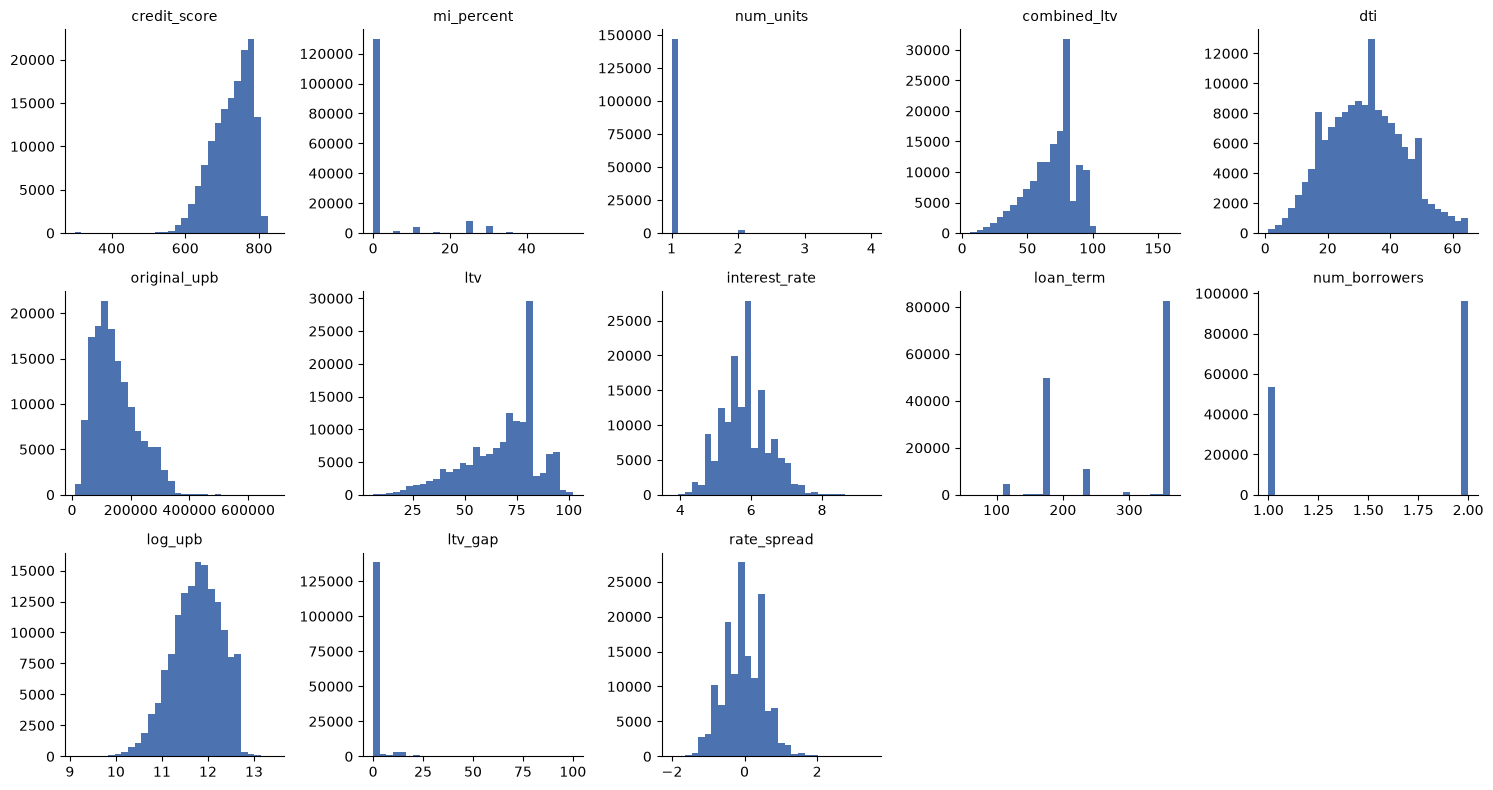

In [3]:
# histograms of the number features
fig, axes = plt.subplots(3, 5, figsize=(15, 8))
for ax, c in zip(axes.ravel(), NUM):
    ax.hist(train[c].dropna(), bins=30, color="#4C72B0")
    ax.set_title(c, fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
for ax in axes.ravel()[len(NUM):]:
    ax.axis("off")
plt.tight_layout()
(ROOT / "results" / "figures").mkdir(parents=True, exist_ok=True)
plt.savefig(ROOT / "results" / "figures" / "feature_histograms.png", dpi=130)
plt.show()

In [4]:
# share of loans in each group for the category features (blanks included)
for c in CAT:
    share = (train[c].value_counts(normalize=True, dropna=False) * 100).round(1)
    print(c, "->", share.head(8).to_dict(), "..." if len(share) > 8 else "")

first_time_homebuyer -> {'N': 95.0, 'Y': 5.0, nan: 0.0} 
occupancy_status -> {'P': 92.7, 'I': 3.8, 'S': 3.5} 
channel -> {'R': 51.7, 'T': 48.1, 'C': 0.1, 'B': 0.1, nan: 0.0} 
property_type -> {'SF': 82.7, 'PU': 10.5, 'CO': 5.9, 'MH': 0.7, 'CP': 0.2, nan: 0.0} 
loan_purpose -> {'N': 44.3, 'C': 29.5, 'P': 26.2} 
prepayment_penalty -> {'N': 99.7, 'Y': 0.3} 
state -> {'CA': 11.6, 'FL': 6.2, 'IL': 5.6, 'MI': 4.9, 'TX': 4.7, 'OH': 4.4, 'NY': 4.1, 'PA': 3.7} ...
state_region -> {'South': 30.1, 'Midwest': 29.7, 'West': 24.0, 'Northeast': 15.9, 'Territory': 0.3} 


## 2. Each feature against default

For each feature I cut it into groups (a number with few values gets one group per value, a value that fills a fifth of the loans, like 0 for mortgage insurance, gets its own group, other numbers are cut into deciles, text features keep their categories with rare ones lumped together, and blanks are their own group) and measure how well the groups separate defaults from non-defaults. Three views:

- **Information value (IV).** A common score in credit scoring. Roughly: below 0.02 useless, 0.02 to 0.1 weak, 0.1 to 0.3 medium, above 0.3 strong.
- **A permutation test for the IV.** IV is never exactly zero, even for pure noise, and with only about 1,000 defaults the noise is not small. So I shuffle the default labels 2,000 times, compute the IV each time, and ask how often noise scores as high as the real feature. That gives a p-value.
- **A standard test.** Mann-Whitney for number features, chi-square for category features.

Many features are tested at once, so some would look significant by luck. I adjust all p-values with the Holm method.

In [5]:
bins, edges, keep = {}, {}, {}
for c in NUM:
    bins[c], edges[c] = numeric_bins(train[c], q=10)
for c in CAT:
    bins[c], keep[c] = categorical_bins(train[c])

# check the fast IV against the plain version on one feature
_, iv_plain = iv_table(bins["credit_score"], y)
assert abs(iv_plain - iv_from_codes(pd.factorize(bins["credit_score"])[0], y)) < 1e-9

In [6]:
rows = []
for c in NUM + CAT:
    iv, noise, p = permutation_iv(bins[c], y, n=2000, seed=1)
    row = {"feature": c, "type": "number" if c in NUM else "category", "IV": iv,
           "noise IV (95th pct)": np.quantile(noise, 0.95), "perm p": p}
    if c in NUM:
        a, b = train.loc[y == 1, c].dropna(), train.loc[y == 0, c].dropna()
        u = stats.mannwhitneyu(a, b)
        auc = u.statistic / (len(a) * len(b))       # chance that a defaulted loan has the higher value
        row.update({"test": "Mann-Whitney", "test p": u.pvalue, "single-feature AUC": max(auc, 1 - auc),
                    "defaults have": "higher values" if auc > 0.5 else "lower values"})
    else:
        ct = pd.crosstab(bins[c], y)
        chi2, pv, _, _ = stats.chi2_contingency(ct)
        row.update({"test": "chi-square", "test p": pv, "Cramer's V": np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))})
    rows.append(row)

res = pd.DataFrame(rows).set_index("feature")
res["perm p (Holm)"] = multipletests(res["perm p"], method="holm")[1]
res["test p (Holm)"] = multipletests(res["test p"], method="holm")[1]
res["strength"] = pd.cut(res["IV"], [-1, 0.02, 0.1, 0.3, 10], labels=["useless", "weak", "medium", "strong"])
res = res.sort_values("IV", ascending=False)
cols = ["type", "IV", "noise IV (95th pct)", "perm p (Holm)", "strength", "test", "test p (Holm)",
        "single-feature AUC", "defaults have", "Cramer's V"]
res[cols].round({"IV": 4, "noise IV (95th pct)": 4, "perm p (Holm)": 4, "test p (Holm)": 4, "single-feature AUC": 3, "Cramer's V": 3})

,type,IV,noise IV (95th pct),perm p (Holm),strength,test,test p (Holm),single-feature AUC,defaults have,Cramer's V
feature,,,,,,,,,,
credit_score,number,1.4442,0.0175,0.0105,strong,Mann-Whitney,0.0000,0.815,lower values,NaN
rate_spread,number,0.6536,0.0164,0.0105,strong,Mann-Whitney,0.0000,0.720,higher values,NaN
interest_rate,number,0.5607,0.0166,0.0105,strong,Mann-Whitney,0.0000,0.703,higher values,NaN
ltv,number,0.5132,0.0161,0.0105,strong,Mann-Whitney,0.0000,0.690,higher values,NaN
combined_ltv,number,0.4236,0.0159,0.0105,strong,Mann-Whitney,0.0000,0.677,higher values,NaN
mi_percent,number,0.4034,0.0122,0.0105,strong,Mann-Whitney,0.0000,0.632,higher values,NaN
loan_term,number,0.3056,0.0092,0.0105,strong,Mann-Whitney,0.0000,0.629,higher values,NaN
num_borrowers,number,0.2930,0.0055,0.0105,medium,Mann-Whitney,0.0000,0.634,lower values,NaN
state,category,0.2337,0.0391,0.0105,medium,chi-square,0.0000,NaN,NaN,0.039


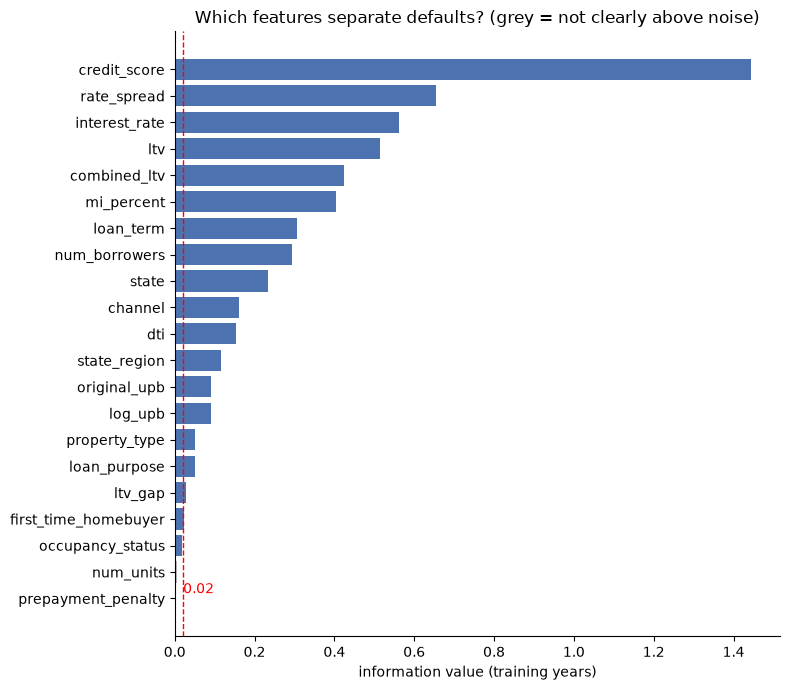

In [7]:
# bar chart of IV; grey bars are not significant against noise
sig = res["perm p (Holm)"] < 0.05
fig, ax = plt.subplots(figsize=(8, 7))
r = res.sort_values("IV")
ax.barh(r.index, r["IV"], color=["#4C72B0" if s else "#BBBBBB" for s in sig[r.index]])
ax.axvline(0.02, color="red", ls="--", lw=1)
ax.text(0.021, 0.2, "0.02", color="red")
ax.set_xlabel("information value (training years)")
ax.set_title("Which features separate defaults? (grey = not clearly above noise)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(ROOT / "results" / "figures" / "feature_iv.png", dpi=130)
plt.show()

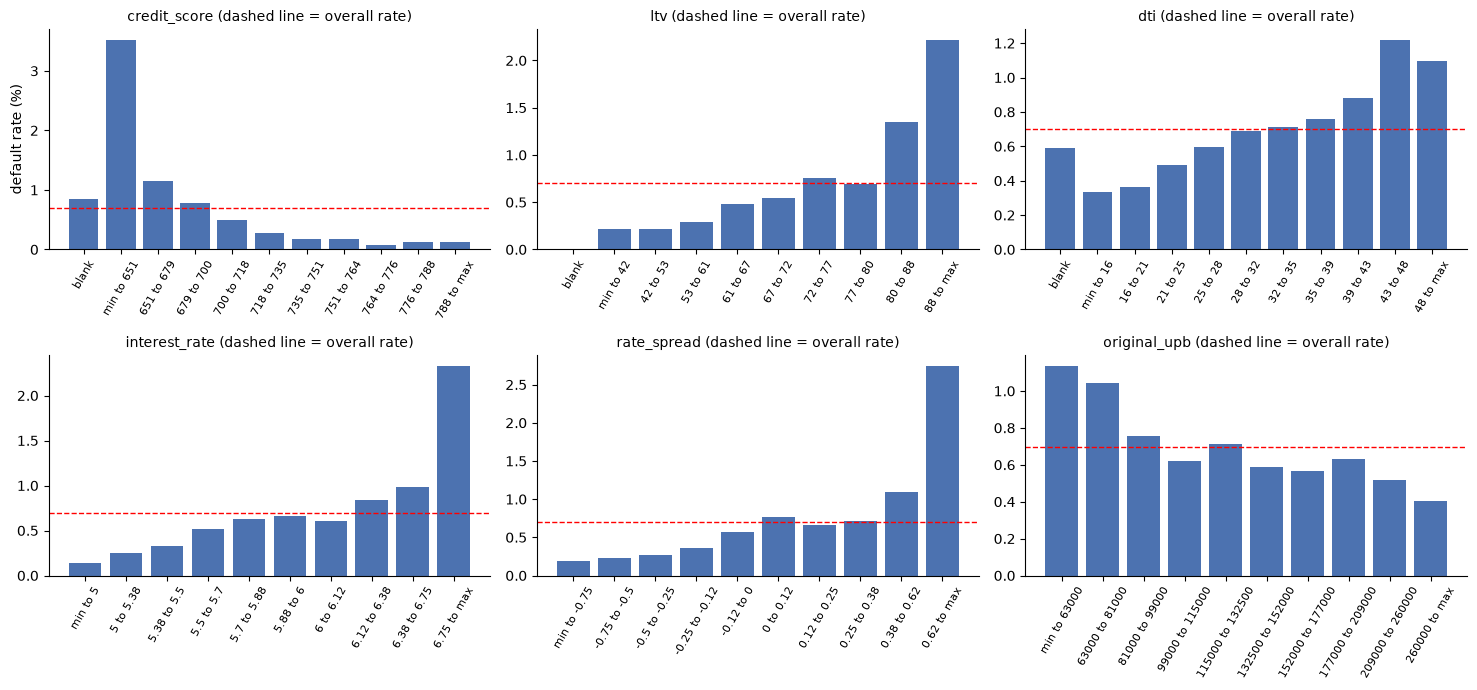

In [8]:
# default rate by group for a few important features: is the pattern sensible and in the expected direction?
def label(c, k):
    if k == -1:
        return "blank"
    lo, hi = edges[c][k], edges[c][k + 1]
    f = (lambda v: "min" if v == -np.inf else "max" if v == np.inf else f"{v:.2f}".rstrip("0").rstrip("."))
    return f"{f(lo)} to {f(hi)}"

show = ["credit_score", "ltv", "dti", "interest_rate", "rate_spread", "original_upb"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.ravel(), show):
    g, _ = iv_table(bins[c], y)
    ax.bar([label(c, k) for k in g.index], g["default_rate_%"], color="#4C72B0")
    ax.axhline(100 * y.mean(), color="red", ls="--", lw=1)
    ax.set_title(f"{c} (dashed line = overall rate)", fontsize=10)
    ax.tick_params(axis="x", rotation=60, labelsize=8)
    ax.spines[["top", "right"]].set_visible(False)
axes[0, 0].set_ylabel("default rate (%)")
plt.tight_layout()
plt.savefig(ROOT / "results" / "figures" / "default_rate_by_feature_group.png", dpi=130)
plt.show()

## 3. Features together

A feature can look useful alone only because it moves with another one (for example loan-to-value and combined loan-to-value). So I look at overlap between features, and then at a joint model.

In [9]:
# pairs of number features that move together (Spearman correlation, training years)
corr = train[NUM].corr(method="spearman")
pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(NUM) for b in NUM[i + 1:] if abs(corr.loc[a, b]) >= 0.6]
pd.DataFrame(pairs, columns=["feature 1", "feature 2", "Spearman"]).sort_values("Spearman", key=abs, ascending=False).round(3).reset_index(drop=True)

,feature 1,feature 2,Spearman
0,original_upb,log_upb,1.000
1,combined_ltv,ltv,0.969
2,interest_rate,rate_spread,0.809


In [10]:
# variance inflation factor: how much of each feature is explained by the others. Above about 5 is a warning
def vif(cols):
    x = train[cols].fillna(train[cols].median())
    x = sm.add_constant((x - x.mean()) / x.std())
    with np.errstate(all="ignore"):
        return pd.Series({c: variance_inflation_factor(x.values, i + 1) for i, c in enumerate(cols)})

set_orig = ["credit_score", "mi_percent", "num_units", "combined_ltv", "dti", "original_upb", "ltv", "interest_rate", "loan_term", "num_borrowers"]
set_new = ["credit_score", "mi_percent", "num_units", "ltv", "ltv_gap", "dti", "log_upb", "rate_spread", "loan_term", "num_borrowers"]
pd.DataFrame({"original number features": vif(set_orig), "with ltv_gap, log_upb, rate_spread": vif(set_new)}).round(2)

,original number features,"with ltv_gap, log_upb, rate_spread"
combined_ltv,19.12,NaN
credit_score,1.11,1.12
dti,1.11,1.11
interest_rate,1.41,NaN
loan_term,1.53,1.77
log_upb,NaN,1.23
ltv,19.90,1.54
ltv_gap,NaN,1.02
mi_percent,1.40,1.40
num_borrowers,1.07,1.07


In [11]:
# a joint logistic regression on the training years: does each feature still matter once the others are in?
# numbers are standardised, so an odds ratio is "per one standard deviation"
num_cols = ["credit_score", "mi_percent", "num_units", "ltv", "ltv_gap", "dti", "log_upb", "rate_spread", "loan_term", "num_borrowers"]
cat_cols = ["first_time_homebuyer", "occupancy_status", "channel", "property_type", "loan_purpose", "prepayment_penalty", "state_region"]
xn = train[num_cols].fillna(train[num_cols].median())
xn = (xn - xn.mean()) / xn.std()
# rare categories are lumped into "other" and the most common category is the baseline, so tiny groups
# with almost no defaults cannot blow up the fit
parts = []
for c in cat_cols:
    s, _ = categorical_bins(train[c], min_share=0.01)
    base = s.value_counts().index[0]
    # rare and blank loans have almost no defaults, which breaks the fit, so they join the baseline here
    s = s.replace({"other": base, "missing": base})
    parts.append(pd.get_dummies(s, prefix=c, dtype=float).drop(columns=f"{c}_{base}"))
xc = pd.concat(parts, axis=1)
X = sm.add_constant(pd.concat([xn, xc], axis=1))
fit = sm.Logit(y, X).fit(disp=0, maxiter=200)
out = pd.DataFrame({"odds ratio": np.exp(fit.params), "low": np.exp(fit.conf_int()[0]), "high": np.exp(fit.conf_int()[1]), "p": fit.pvalues})
out["p (Holm)"] = multipletests(out["p"], method="holm")[1]
print(f"loans: {int(fit.nobs):,} | pseudo R-squared: {fit.prsquared:.3f} | converged: {fit.mle_retvals['converged']}")
out.drop(index="const").sort_values("p").round(4)

loans: 150,000 | pseudo R-squared: 0.190 | converged: True


,odds ratio,low,high,p,p (Holm)
credit_score,0.4824,0.4603,0.5056,0.0000,0.0000
num_borrowers,0.6759,0.6340,0.7206,0.0000,0.0000
rate_spread,1.3719,1.2820,1.4680,0.0000,0.0000
channel_T,1.7779,1.5487,2.0412,0.0000,0.0000
state_region_West,0.5370,0.4364,0.6608,0.0000,0.0000
log_upb,0.8214,0.7634,0.8839,0.0000,0.0000
mi_percent,1.1687,1.0994,1.2423,0.0000,0.0000
loan_term,1.2665,1.1506,1.3941,0.0000,0.0000
dti,1.1797,1.1014,1.2636,0.0000,0.0000
property_type_CO,0.4355,0.3078,0.6162,0.0000,0.0000


In [12]:
# does a whole feature still matter once all the others are in the model? Refit without it and compare
# (likelihood-ratio test; a category feature is dropped with all of its columns at once)
groups = {c: [c] for c in num_cols}
for c in cat_cols:
    groups[c] = [col for col in X.columns if col.startswith(c + "_")]
rows = []
for name, cols in groups.items():
    reduced = sm.Logit(y, X.drop(columns=cols)).fit(disp=0, maxiter=200)
    lr = 2 * (fit.llf - reduced.llf)
    rows.append({"feature": name, "columns": len(cols), "LR chi-square": lr, "p": stats.chi2.sf(lr, len(cols))})
lr_tab = pd.DataFrame(rows).set_index("feature")
lr_tab["p (Holm)"] = multipletests(lr_tab["p"], method="holm")[1]
lr_tab.sort_values("p").round(4)

,columns,LR chi-square,p,p (Holm)
feature,,,,
credit_score,1,779.4392,0.0000,0.0000
num_borrowers,1,148.6199,0.0000,0.0000
rate_spread,1,81.3275,0.0000,0.0000
channel,1,70.0113,0.0000,0.0000
property_type,2,42.5138,0.0000,0.0000
state_region,3,41.3601,0.0000,0.0000
log_upb,1,27.5499,0.0000,0.0000
mi_percent,1,24.7313,0.0000,0.0000
loan_term,1,24.2953,0.0000,0.0000


## 4. Do blanks carry information?

For the features with blanks: is the default rate different when the value is missing? A feature with blanks is worth a "was missing" flag only if the answer is yes. Fisher's exact test checks whether the difference is more than chance.

In [13]:
rows = []
for c in [c for c in NUM + CAT if train[c].isna().any()]:
    m = train[c].isna()
    ct = [[int(((y == 1) & m).sum()), int(((y == 0) & m).sum())], [int(((y == 1) & ~m).sum()), int(((y == 0) & ~m).sum())]]
    rows.append({"feature": c, "blank loans": int(m.sum()), "default rate when blank %": 100 * y[m].mean(),
                 "default rate when filled %": 100 * y[~m].mean(), "Fisher p": stats.fisher_exact(ct)[1]})
blank_tab = pd.DataFrame(rows).set_index("feature")
blank_tab.round(4)

,blank loans,default rate when blank %,default rate when filled %,Fisher p
feature,,,,
credit_score,472,0.8475,0.6982,0.5769
mi_percent,3,0.0000,0.6987,1.0000
num_units,6,0.0000,0.6987,1.0000
combined_ltv,11,0.0000,0.6987,1.0000
dti,2871,0.5921,0.7007,0.5715
ltv,10,0.0000,0.6987,1.0000
num_borrowers,37,0.0000,0.6988,1.0000
ltv_gap,11,0.0000,0.6987,1.0000
first_time_homebuyer,28,0.0000,0.6988,1.0000


## 5. How much does each feature shift between years? (for information only)

The population stability index (PSI) compares the distribution of a feature in each year with its distribution in the training years. Below 0.1 is stable, 0.1 to 0.25 is a moderate shift, above 0.25 is a large shift. This table is **not used to choose features**. It is here because the project is about what happens when the inputs shift.

In [14]:
rows = []
for c in NUM + CAT:
    row = {"feature": c}
    for yr in range(2002, 2008):
        sub = full[full["vintage"] == yr]
        if c in NUM:
            new = numeric_bins(sub[c], edges=edges[c])[0]
        else:
            new = categorical_bins(sub[c], keep=keep[c])[0]
        row[yr] = psi(bins[c], new)
    rows.append(row)
psi_tab = pd.DataFrame(rows).set_index("feature")
psi_tab["max 2006-07"] = psi_tab[[2006, 2007]].max(axis=1)
psi_tab.sort_values("max 2006-07", ascending=False).round(3)

,2002,2003,2004,2005,2006,2007,max 2006-07
feature,,,,,,,
interest_rate,0.879,0.439,0.267,0.433,1.758,1.448,1.758
loan_term,0.001,0.023,0.036,0.224,0.462,0.560,0.560
loan_purpose,0.002,0.052,0.060,0.204,0.411,0.331,0.411
rate_spread,0.032,0.046,0.080,0.251,0.211,0.122,0.211
dti,0.004,0.014,0.015,0.070,0.130,0.132,0.132
log_upb,0.003,0.002,0.009,0.066,0.109,0.130,0.130
original_upb,0.003,0.002,0.009,0.066,0.109,0.130,0.130
combined_ltv,0.002,0.014,0.014,0.021,0.072,0.123,0.123
ltv_gap,0.010,0.002,0.008,0.021,0.093,0.090,0.093


## 6. Choosing the features

Rules, applied to the numbers above (training years only):

1. **Signal.** A feature must beat noise: Holm-adjusted permutation p-value below 0.05.
2. **For the logistic list only:** also an IV of at least 0.02, so weak features do not clutter an interpretable model.
3. **Overlap.** If two number features have a Spearman correlation of 0.8 or more, keep the one with the higher IV.
4. **Original or engineered version?** For balance (`original_upb` or `log_upb`) keep the one with the higher IV. For state, use the 5 regions in the logistic list even though the 54 states have a higher IV: state effects learned in the calm years (for example the Rust Belt) may not carry over to the crash years, which hit other states. The boosting list keeps both, and I will test with and without state. For the rate, keep `rate_spread` if it qualifies, because it measures how expensive a loan was for its year and does not reveal the year itself. A model that can read the year from the interest rate may behave differently in a stressed year, and I want that to be my choice and not an accident.
5. **Gradient boosting list:** every feature that beats noise (rule 1), original and engineered versions both, because boosting copes with overlap.
6. A "was missing" flag is added only if loans with a blank default at a different rate than the others (Fisher p-value below 0.05 in section 4). Otherwise blanks are simply filled in (logistic regression) or left as they are (boosting).
7. **For the logistic list only:** a feature must still matter once the others are in the model (likelihood-ratio test in section 3, Holm p-value below 0.05).

The year-linked features (large PSI in 2006-2007) are recorded so that I can test the models with and without them.

In [15]:
sig = res["perm p (Holm)"] < 0.05
notes = {}

# rules 1 and 2: signal and IV
cand = [c for c in res.index if sig[c] and res.loc[c, "IV"] >= 0.02]
for c in res.index:
    if c not in cand:
        notes[c] = "not clearly above noise" if not sig[c] else "IV below 0.02"

# rule 4: original or engineered version
def pick(a, b, prefer_b=False):
    ina, inb = a in cand, b in cand
    if ina and inb:
        keep_, drop_ = (b, a) if (prefer_b or res.loc[b, "IV"] >= res.loc[a, "IV"]) else (a, b)
        cand.remove(drop_)
        notes[drop_] = f"replaced by {keep_}"
pick("original_upb", "log_upb")
pick("state", "state_region", prefer_b=True)
pick("interest_rate", "rate_spread", prefer_b=True)

# rule 3: overlap between number features
changed = True
while changed:
    changed = False
    nums = [c for c in cand if c in NUM]
    best = max(((abs(corr.loc[a, b]), a, b) for i, a in enumerate(nums) for b in nums[i + 1:]), default=(0, None, None))
    if best[0] >= 0.8:
        _, a, b = best
        drop_, keep_ = (a, b) if res.loc[a, "IV"] < res.loc[b, "IV"] else (b, a)
        cand.remove(drop_)
        notes[drop_] = f"overlaps with {keep_} (correlation {best[0]:.2f})"
        changed = True

# rule 7: it must still matter once the other features are in the joint model
for c in list(cand):
    if c in lr_tab.index and lr_tab.loc[c, "p (Holm)"] >= 0.05:
        cand.remove(c)
        notes[c] = "adds nothing once the other features are in the model"

flags = {"credit_score": "credit_score_missing", "dti": "dti_missing"}
flag_ok = {c: f for c, f in flags.items() if c in blank_tab.index and blank_tab.loc[c, "Fisher p"] < 0.05}   # rule 6
set_A = cand + [f for c, f in flag_ok.items() if c in cand]
set_B = [c for c in res.index if sig[c]] + [f for c, f in flag_ok.items() if c in res.index[sig]]
print("missing flags kept:", list(flag_ok.values()) or "none")
year_linked = list(psi_tab.index[psi_tab["max 2006-07"] >= 0.25])

decision = res[["type", "IV", "perm p (Holm)", "strength"]].copy()
decision["max PSI 2006-07"] = psi_tab["max 2006-07"]
decision["in logistic list"] = [c in set_A for c in decision.index]
decision["in boosting list"] = [c in set_B for c in decision.index]
decision["note"] = [notes.get(c, "") for c in decision.index]
decision["year-linked"] = [c in year_linked for c in decision.index]
print("logistic list:", set_A)
print("boosting list:", set_B)
print("year-linked  :", year_linked)
decision.round(4)

missing flags kept: none
logistic list: ['credit_score', 'rate_spread', 'ltv', 'mi_percent', 'loan_term', 'num_borrowers', 'channel', 'dti', 'state_region', 'log_upb', 'property_type', 'loan_purpose']
boosting list: ['credit_score', 'rate_spread', 'interest_rate', 'ltv', 'combined_ltv', 'mi_percent', 'loan_term', 'num_borrowers', 'state', 'channel', 'dti', 'state_region', 'original_upb', 'log_upb', 'property_type', 'loan_purpose', 'ltv_gap', 'first_time_homebuyer', 'occupancy_status']
year-linked  : ['interest_rate', 'loan_term', 'loan_purpose']


,type,IV,perm p (Holm),strength,max PSI 2006-07,in logistic list,in boosting list,note,year-linked
feature,,,,,,,,,
credit_score,number,1.4442,0.0105,strong,0.0518,True,True,,False
rate_spread,number,0.6536,0.0105,strong,0.2110,True,True,,False
interest_rate,number,0.5607,0.0105,strong,1.7576,False,True,replaced by rate_spread,True
ltv,number,0.5132,0.0105,strong,0.0659,True,True,,False
combined_ltv,number,0.4236,0.0105,strong,0.1232,False,True,overlaps with ltv (correlation 0.97),False
mi_percent,number,0.4034,0.0105,strong,0.0594,True,True,,False
loan_term,number,0.3056,0.0105,strong,0.5598,True,True,,True
num_borrowers,number,0.2930,0.0105,medium,0.0550,True,True,,False
state,category,0.2337,0.0105,medium,0.0636,False,True,replaced by state_region,False


In [16]:
# save the lists and the summary so the model notebooks use exactly these
(ROOT / "data" / "processed").mkdir(parents=True, exist_ok=True)
json.dump({"logistic": set_A, "boosting": set_B, "year_linked": year_linked,
           "chosen_on": "training years 2002-2004 only"},
          open(ROOT / "data" / "processed" / "feature_sets.json", "w", encoding="utf8"), indent=2)
(ROOT / "results" / "tables").mkdir(parents=True, exist_ok=True)
decision.round(4).to_csv(ROOT / "results" / "tables" / "feature_summary.csv")
print("saved feature_sets.json and feature_summary.csv")

saved feature_sets.json and feature_summary.csv


## 7. What I see

**Strength of each feature (training years: 150,000 loans, 1,048 defaults)**
- Credit score is by far the strongest: information value 1.44 and a single-feature AUC of 0.82 (lower scores default more). Next come the rate relative to its year (0.65), the interest rate (0.56), loan-to-value (0.51), combined loan-to-value (0.42), mortgage insurance percentage (0.40), loan term (0.31) and number of borrowers (0.29).
- Number of units and the prepayment penalty are not clearly above noise. Occupancy status is statistically significant but weak (IV 0.017, below the 0.02 line).
- The direction of every strong feature makes sense: defaults go with lower credit scores, higher loan-to-value, higher debt-to-income, higher rates, a single borrower and smaller loans.

**Features together**
- Loan-to-value and combined loan-to-value move almost together (correlation 0.97, variance inflation 19.9 and 19.1, far above the warning level of 5). Using loan-to-value with `ltv_gap` instead brings every variance inflation factor down to 1.8 or less. `original_upb` and `log_upb` order the loans identically, so only one is needed.
- In the joint logistic model (it converged) the features that still matter once the others are in are: credit score, number of borrowers, rate spread, channel, property type, region, balance, mortgage insurance percentage, loan term, debt-to-income, loan-to-value and loan purpose (likelihood-ratio test, Holm p below 0.05). `ltv_gap`, first-time homebuyer, occupancy and number of units add nothing there.
- The pseudo R-squared of 0.19 is measured on the same loans the model was fitted on, so it says nothing yet about prediction.

**Blanks**
- I found no sign that a blank carries information. Loans with a blank credit score default at 0.85% against 0.70% for the rest (p = 0.58), and loans with a blank debt-to-income at 0.59% against 0.70% (p = 0.57). So there are no "was missing" flags.

**Shift between years (for information only)**
- Large shifts in 2006-2007: interest rate (PSI 1.76), loan term (0.56) and loan purpose (0.41). The rate spread shifts moderately (0.21), and every other feature is below 0.15.
- The interest rate is really a marker of the year: even inside the training years, 2002 has a PSI of 0.88 against the pooled training years. That is why the logistic list uses the rate spread instead.
- Loan term and loan purpose also shift because the early years were dominated by refinancing. I will test the models with and without these three features.

**The two lists** (saved in `data/processed/feature_sets.json`)
- Logistic (12): credit_score, rate_spread, ltv, mi_percent, loan_term, num_borrowers, channel, dti, state_region, log_upb, property_type, loan_purpose.
- Boosting (19): everything above plus interest_rate, combined_ltv, state, original_upb, ltv_gap, first_time_homebuyer and occupancy_status.
- To test with and without: interest_rate, loan_term, loan_purpose, and state.

**Cautions**
- With 1,048 defaults, a small real effect can be missed and a lucky one can look real. The Holm adjustment and the permutation test help, but they do not create data.
- All of this is measured on the training years. Whether the chosen features hold up in 2006-2007 is what the models will show.
- Keeping `state` out of the logistic list was a judgement call. The data alone preferred it (IV 0.23 against 0.12 for the regions).
- The cut-offs (IV 0.02, correlation 0.8, variance inflation 5, p below 0.05) are common conventions, not laws.
- Not looked at yet: non-linear effects and interactions, and how to bin credit score for a scorecard.